# Week 5, Task 1: first coupled runs with a slab ocean

Two JAX-ESM (JEM) configurations, both SPEEDY T31L8 with daily coupling and CO2 = 420 ppmv
(`jcm.forcing.DEFAULT_CO2_VMR_PPMV`, as in the Week 4 control):

| Run | Command | Components | Ocean |
|---|---|---|---|
| aquaplanet-slab | `python -m jem.main +configuration=aquaplanet-slab coupled_run=long_run coupled_run.total_time="360 days"` | atm, ocn, seaice | free slab, no forcing term |
| earth-slab | `python -m jem.main +configuration=earth-slab coupled_run=long_run coupled_run.total_time="360 days"` | atm, ocn, lnd, seaice | slab relaxed to an SST climatology, τ = 30 days |

The brief's quick start (`coupled_run=short_run`, 2 days) ran for both configurations in about 14 s on a laptop.
Two days shows nothing about the ocean, so the analysis uses the 360-day runs (12 minutes each on an M2 CPU, run at
the same time). Each output record is a **30-day-window mean**, not a calendar month.

Data: `results/w5-task1_aquaplanet.nc`, `results/w5-task1_earth.nc`, made by `nrp/extract_jem.py`. Ocean fields
(`sst`, `mld`, `hfds_up`, `frzmlt`) are NaN over land. Both runs start from an isothermal atmosphere at rest, so the
first 30-day window is atmospheric spin-up.

In [1]:
import os

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

REPO = os.path.abspath("..")          # this notebook lives in <repo>/notebooks
assert os.path.exists(f"{REPO}/results/w5-task1_aquaplanet.nc"), "run from the notebooks/ folder"
FIGS = f"{REPO}/figures"
RESULTS = f"{REPO}/results"

# jem/constants.py at the pinned jax-esm commit
RHO_O = 1025.0      # kg m-3
CP_O = 3985.0       # J kg-1 K-1
T_FREEZE = 271.35   # K
DAY = 86400.0

aqua = xr.open_dataset(f"{RESULTS}/w5-task1_aquaplanet.nc")
earth = xr.open_dataset(f"{RESULTS}/w5-task1_earth.nc")
for ds in (aqua, earth):
    ds["pr"] = (ds.pr * DAY).assign_attrs(units="mm/day")
RUNS = {"aquaplanet-slab": aqua, "earth-slab": earth}
print({k: dict(v.sizes) for k, v in RUNS.items()})
print("record mid-times:", aqua.time.dt.strftime("%m-%d").values)


def gmean(da, mask=None):
    w = np.cos(np.deg2rad(da.lat)) * (xr.ones_like(da.isel(time=0, drop=True)) if "time" in da.dims else 1)
    if mask is not None:
        w = w.where(mask, 0)
    return da.weighted(w.fillna(0)).mean(("lat", "lon"))

{'aquaplanet-slab': {'time': 12, 'lat': 48, 'lon': 96}, 'earth-slab': {'time': 12, 'lat': 48, 'lon': 96}}
record mid-times: ['01-16' '02-15' '03-16' '04-15' '05-15' '06-14' '07-14' '08-13' '09-12'
 '10-12' '11-11' '12-11']


## 1. The slab-ocean equation (`jem/components/slab/slab_ocean_model/slab_ocean_model.py`)

The state is only the SST, $T$. Each coupling step (1 day) does

$$\rho c_p h \,\frac{dT}{dt} = -F_\uparrow + \rho c_p h \cdot \text{forcing}$$

- $F_\uparrow$ is the net surface heat flux from the atmosphere, **upward positive** (radiation + sensible + latent).
- $\rho = 1025$ kg m⁻³ and $c_p = 3985$ J kg⁻¹ K⁻¹ (`jem/constants.py`); $h$ is the mixed-layer depth.
- `forcing_method` (static) selects the extra term:
  - `"none"` (aquaplanet-slab): no extra term.
  - `"qflux"`: $+Q/(\rho c_p h)$, where $Q$ is a 12-month `qflux` climatology from `q_flux_file`. Positive $Q$ warms the slab.
  - `"relaxation"` (earth-slab): $-(T - T_\text{clim})/\tau$. The code steps it with backward Euler, so it appears as the factor $1/(1 + \Delta t/\tau)$.
- After the update, the code clamps $T$ at the freezing point (271.35 K). It reports the removed heat as `ice_frazil_melt_energy`, and the sea-ice component uses this to grow or melt ice.

**Mixed-layer depth.** Nothing in the ocean physics sets $h$: it is a fixed profile of two parameters,
$h = h_\max + (h_\min - h_\max)\cos^3(\text{lat})$, with $h_\min = 40$ m (equator) and $h_\max = 60$ m (poles).
It does not change with wind, season or stratification. The code recalculates it every step from
`carry["params"]` only so that `jax.grad` with respect to the two depths is not zero (Week 6). The cell below checks the
output against this formula and calculates the heat capacity.

SlabOceanParameters(relaxation_time=5184000.0, mixed_layer_depth_min=40.0, mixed_layer_depth_max=60.0, initial_sst=288.15, forcing_method='none', ocean_mask_value=0.0)
max |output - formula| = 1.620599801555045e-05 m
max over time of the change in mld: 0.0 m
global-mean h = 48.2 m, heat capacity C = 1.97e+08 J m-2 K-1
  lambda = 1.0 W m-2 K-1 -> e-folding time C/lambda = 6.2 yr
  lambda = 1.5 W m-2 K-1 -> e-folding time C/lambda = 4.2 yr
  lambda = 2.0 W m-2 K-1 -> e-folding time C/lambda = 3.1 yr


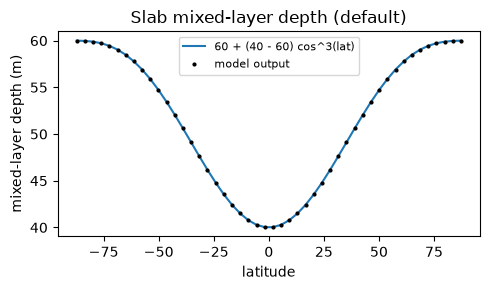

In [2]:
from jem.components.slab import SlabOceanParameters

p = SlabOceanParameters.default()
print(p)
lat = aqua.lat
h_formula = p.mixed_layer_depth_max + (p.mixed_layer_depth_min - p.mixed_layer_depth_max) * np.cos(np.deg2rad(lat)) ** 3
h_out = aqua.mld.isel(time=0).mean("lon")
print("max |output - formula| =", float(abs(h_out - h_formula).max()), "m")
print("max over time of the change in mld:", float(abs(aqua.mld - aqua.mld.isel(time=0)).max()), "m")

C = RHO_O * CP_O * gmean(aqua.mld.isel(time=0))
print(f"global-mean h = {float(gmean(aqua.mld.isel(time=0))):.1f} m, "
      f"heat capacity C = {float(C):.2e} J m-2 K-1")
for lam in (1.0, 1.5, 2.0):
    print(f"  lambda = {lam} W m-2 K-1 -> e-folding time C/lambda = {float(C) / lam / (365 * DAY):.1f} yr")

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(lat, h_formula, label="60 + (40 - 60) cos^3(lat)")
ax.plot(lat, h_out, "k.", ms=4, label="model output")
ax.set(xlabel="latitude", ylabel="mixed-layer depth (m)", title="Slab mixed-layer depth (default)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"{FIGS}/week5_mld.png", dpi=150)

## 2. Global means through the year

The first window (days 0–30) is the spin-up of the isothermal atmosphere: OLR is about 300 W m⁻² and TOA net is about −50 W m⁻².
After that, the TOA net flux has a seasonal cycle, so compare the mean over windows 2–12, not single windows.

                              first 30 d   last 30 d
aquaplanet-slab
  SST, ocean mean (K)             293.05      295.12
  tas, global (K)                 290.54      292.99
  TOA net down (W m-2)            -55.04       11.69
  sea-ice area (% of globe)         0.00        0.00
  precip, global (mm/day)           1.76        3.54
earth-slab
  SST, ocean mean (K)             291.57      291.59
  tas, global (K)                 287.26      286.62
  TOA net down (W m-2)            -46.58       13.39
  sea-ice area (% of globe)         2.67        3.36
  precip, global (mm/day)           1.54        2.94


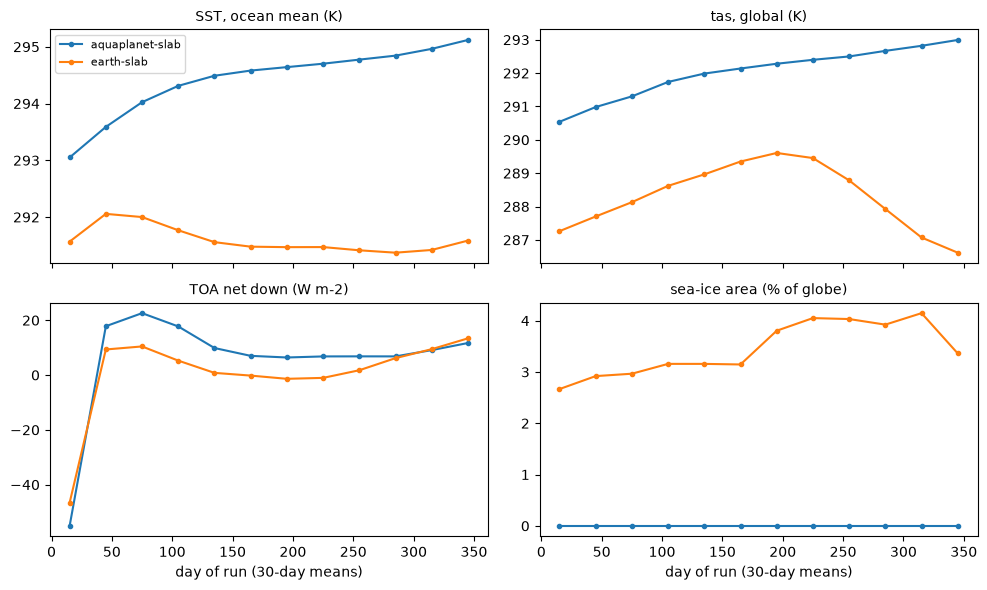

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
rows = {}
for name, ds in RUNS.items():
    ocean = ds.ocean_mask == 1
    ice_area = gmean(ds.sic.fillna(0), ocean) * float(ocean.weighted(np.cos(np.deg2rad(ds.lat))).mean())
    series = {
        "SST, ocean mean (K)": gmean(ds.sst, ocean),
        "tas, global (K)": gmean(ds.tas),
        "TOA net down (W m-2)": gmean(ds.rtnt),
        "sea-ice area (% of globe)": 100 * ice_area,
    }
    days = (ds.time - ds.time[0]).dt.days + 15
    for ax, (k, v) in zip(axs.flat, series.items()):
        ax.plot(days, v, "o-", ms=3, label=name)
        ax.set_title(k, fontsize=10)
    rows[name] = {k: (float(v[0]), float(v[-1])) for k, v in series.items()}
    rows[name]["precip, global (mm/day)"] = (float(gmean(ds.pr)[0]), float(gmean(ds.pr)[-1]))
for ax in axs[1]:
    ax.set_xlabel("day of run (30-day means)")
axs[0, 0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"{FIGS}/week5_global_timeseries.png", dpi=150)

print(f"{'':28s}{'first 30 d':>12s}{'last 30 d':>12s}")
for name, r in rows.items():
    print(name)
    for k, (a, b) in r.items():
        print(f"  {k:26s}{a:12.2f}{b:12.2f}")

- **Aquaplanet: not in equilibrium.** TOA net is **+11.1 W m⁻²** (mean of windows 2–12) and the ocean-mean SST rises
  from 293.6 K to 295.1 K over those 300 days. Energy check: with $C = 1.97\times10^8$ J m⁻² K⁻¹ and an all-ocean planet,
  11 W m⁻² gives $11 / C \approx 1.8$ K yr⁻¹, which agrees with the measured rise (about 1.8 K yr⁻¹). The free slab must still warm
  until the TOA flux goes to zero. With an e-folding time of about 3–6 years (cell above), that needs a run of a few decades.
- **Earth-like: the relaxation holds the SST.** The ocean-mean SST stays within 0.6 K of its first value all year.
  But TOA net is **+4.9 W m⁻²**, the same imbalance as the Week 4 fixed-SST control (+4.9 W m⁻²). So the relaxation
  removes this energy from the ocean (section 4), and a fixed SST did the same thing in Week 4.
- No sea ice forms on the aquaplanet in year 1. Its initial profile (288–298 K) starts the poles 17 K above freezing.
- Global precipitation (last window): aquaplanet 3.5 mm/day, earth-slab 2.9 mm/day (Week 4 control: 2.92).

## 3. Aquaplanet: what the free slab does

equator-to-pole SST difference, last 30 days: 24.5 K
hemispheric asymmetry |SST(N) - SST(S)|, max over latitudes, last 30 days: 2.17 K


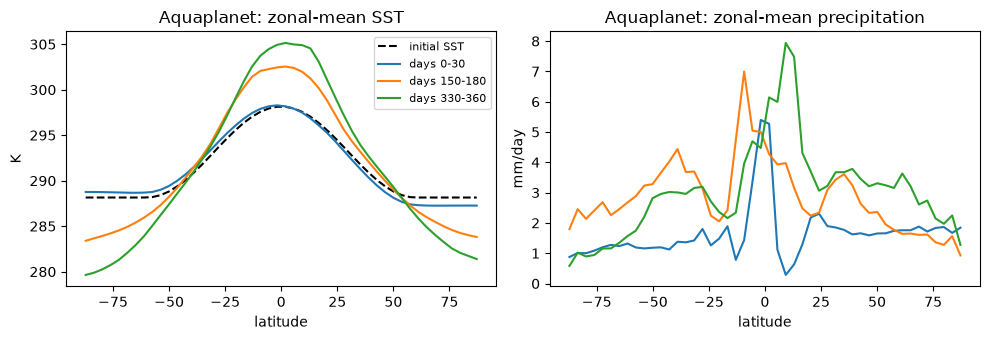

In [4]:
from jem.utils.idealized_distribution import positive_cosine_cubic_latitude_squared

sst0 = p.initial_sst + 10.0 * positive_cosine_cubic_latitude_squared(np.deg2rad(lat.values))
zm = aqua.mean("lon")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].plot(lat, np.maximum(sst0, T_FREEZE), "k--", label="initial SST")
for i in (0, 5, 11):
    axs[0].plot(lat, zm.sst.isel(time=i), label=f"days {30 * i}-{30 * i + 30}")
    axs[1].plot(lat, zm.pr.isel(time=i), label=f"days {30 * i}-{30 * i + 30}")
axs[0].set(xlabel="latitude", ylabel="K", title="Aquaplanet: zonal-mean SST")
axs[1].set(xlabel="latitude", ylabel="mm/day", title="Aquaplanet: zonal-mean precipitation")
axs[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"{FIGS}/week5_aquaplanet_zonal.png", dpi=150)

print("equator-to-pole SST difference, last 30 days:",
      round(float(zm.sst.isel(time=-1).sel(lat=slice(-5, 5)).mean() - zm.sst.isel(time=-1).isel(lat=[0, -1]).mean()), 1), "K")
print("hemispheric asymmetry |SST(N) - SST(S)|, max over latitudes, last 30 days:",
      round(float(abs(zm.sst.isel(time=-1) - zm.sst.isel(time=-1)[::-1].values).max()), 2), "K")

The initial SST profile has only 10 K from the equator to the pole. In one year the equator warms to about 305 K and
the poles cool to about 281 K, so the gradient increases to about 25 K. No ocean heat transport is present, so
the slab must balance the local surface flux in each column by itself. The two hemispheres stay within about 2 K of each other.
The initial state is symmetric, so this difference is probably the seasonal cycle (the last window is NH winter).

## 4. Earth-like: what the relaxation does, and what a Q-flux is

In the relaxed slab, the relaxation term is a heat flux into the mixed layer:
$Q_\text{relax} = -\rho c_p h\,(T - T_\text{clim})/\tau$. Two independent estimates follow:

1. From the SST bias against the relaxation target (rebuilt below with the same interpolation as jem).
2. From the energy budget of the slab, $Q_\text{budget} = C\,dT/dt + F_\uparrow$. This estimate does not use the target.

Note on the target: `evaluate_cyclic_linear` puts the 12 monthly records at year fractions 0, 1/12, …, i.e. at the
**start** of each month. A monthly mean represents the middle of its month, so the target lags the observed seasonal
cycle by about half a month. This is how jem works; we did not change it.

In [5]:
# The relaxation target, rebuilt the way jem does it: the 12 records of `sst` in the
# forcing file, floored at freezing, placed at year fractions 0, 1/12, ..., 11/12
# (jem.utils.cycles.evaluate_cyclic_linear) and linearly interpolated. It is
# evaluated each day and averaged over the same 30-day windows as the output.
import jcm, pandas as pd
clim_file = f"{os.path.dirname(jcm.__file__)}/data/bc/t30/clim/forcing.nc"
sst_clim = np.maximum(xr.open_dataset(clim_file).sst.transpose("lat", "lon", "time").values, T_FREEZE)

days = pd.date_range("2000-01-01", periods=360, freq="D")
frac = (days.day_of_year.values - 1) / 366.0           # 2000 is a leap year
pos = frac * 12
i0 = np.floor(pos).astype(int) % 12
a = pos - np.floor(pos)
daily = (1 - a) * sst_clim[..., i0] + a * sst_clim[..., (i0 + 1) % 12]   # (lat, lon, day)
target = xr.DataArray(daily.reshape(48, 96, 12, 30).mean(-1), dims=("lat", "lon", "time"),
                      coords={"lat": earth.lat, "lon": earth.lon, "time": earth.time}).transpose("time", "lat", "lon")
target = target.where(earth.ocean_mask == 1)

ocean = earth.ocean_mask == 1
bias = earth.sst - target
ice_free = (earth.sic.fillna(0).max("time") == 0) & ocean
print("SST - target, ocean mean, each 30-day window (K):", gmean(bias, ocean).round(2).values)
print("  ice-free ocean only:", gmean(bias, ice_free).round(2).values)
print("annual-mean |SST - target|, ocean RMS:", round(float(np.sqrt(gmean(bias.mean("time") ** 2, ocean))), 2), "K")

SST - target, ocean mean, each 30-day window (K): [0.12 0.52 0.47 0.32 0.17 0.08 0.02 0.02 0.08 0.18 0.27 0.33]
  ice-free ocean only: [ 0.1   0.52  0.49  0.34  0.16  0.   -0.11 -0.1   0.03  0.19  0.31  0.34]
annual-mean |SST - target|, ocean RMS: 0.4 K


Q_relax: ice-free ocean mean  -12.7 W m-2, RMS  27.7 W m-2
Q_budget: ice-free ocean mean  -14.9 W m-2, RMS  28.4 W m-2
pattern correlation, ice-free ocean: 0.92


zonal-mean Q_relax (W m-2) at {-60: 6.0, -40: 13.0, -20: -3.0, 0: -39.0, 20: -16.0, 40: -2.0, 60: -1.0}


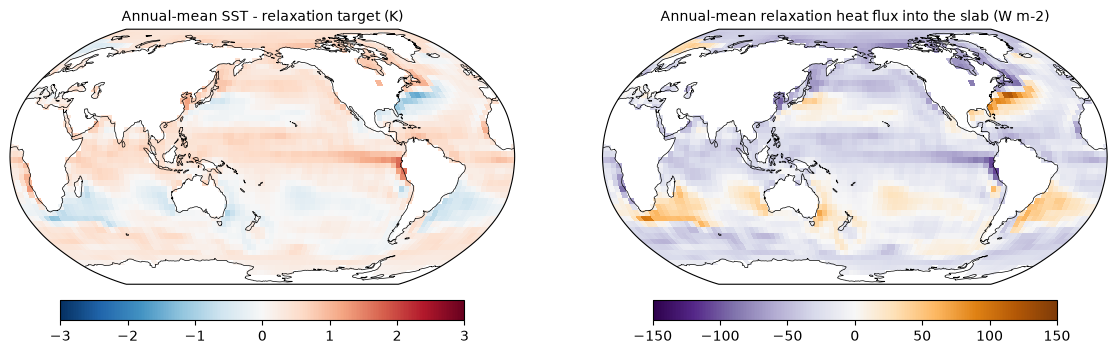

In [6]:
# What the relaxation does, as a heat flux into the mixed layer (positive warms):
#   Q_relax = -C (SST - target) / tau
# and, independently, from the slab's energy budget over the year:
#   Q_budget = C dSST/dt + F_up    (F_up = hfds_up, the upward surface flux)
# Annual means. Only ice-free ocean: under ice the freezing clamp adds a third term.
C_map = RHO_O * CP_O * earth.mld.isel(time=0)
tau = 30 * DAY                                       # earth-slab.yaml: relaxation_time = 30 days
q_relax = (-C_map * bias / tau).mean("time")
# dSST/dt over the year from the first and last 30-day means (330 days apart).
dsst = (earth.sst.isel(time=-1) - earth.sst.isel(time=0)) / (330 * DAY)
q_budget = C_map * dsst + earth.hfds_up.mean("time")

for name, q in (("Q_relax", q_relax), ("Q_budget", q_budget)):
    print(f"{name}: ice-free ocean mean {float(gmean(q, ice_free)):6.1f} W m-2, "
          f"RMS {float(np.sqrt(gmean(q ** 2, ice_free))):5.1f} W m-2")
qa, qb = q_relax.where(ice_free), q_budget.where(ice_free)
print("pattern correlation, ice-free ocean:", round(float(xr.corr(qa, qb)), 2))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6), subplot_kw={"projection": ccrs.Robinson(central_longitude=180)})
for ax, da, ttl, lim, cm in (
        (axs[0], bias.mean("time"), "Annual-mean SST - relaxation target (K)", 3, "RdBu_r"),
        (axs[1], q_relax, "Annual-mean relaxation heat flux into the slab (W m-2)", 150, "PuOr_r")):
    im = ax.pcolormesh(da.lon, da.lat, da, transform=ccrs.PlateCarree(), cmap=cm, vmin=-lim, vmax=lim)
    ax.coastlines(lw=0.5)
    ax.set_title(ttl, fontsize=10)
    fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.7, pad=0.05)
fig.tight_layout()
fig.savefig(f"{FIGS}/week5_earth_relaxation.png", dpi=150)

zq = q_relax.where(ice_free).mean("lon")
print("zonal-mean Q_relax (W m-2) at", {int(l): round(float(zq.sel(lat=l, method='nearest')), 0) for l in (-60, -40, -20, 0, 20, 40, 60)})

- The two estimates agree: means of −12.7 and −14.9 W m⁻² over ice-free ocean, and a pattern correlation of 0.92. This
  agreement confirms the sign convention ($F_\uparrow$ upward positive) and the relaxation formula read from the code.
- The SST stays 0.0–0.5 K warmer than its target (RMS of the annual mean 0.4 K). A steady bias $\Delta T$ needs
  $Q = C\Delta T/\tau$, so 0.17 K × $C$ / 30 days ≈ 13 W m⁻², which agrees with the mean above.
- **The pattern of $Q_\text{relax}$ is the ocean heat transport that the slab cannot calculate.** The relaxation takes
  heat out at the equator (about −39 W m⁻² in the zonal mean, below −100 W m⁻² in the east Pacific) and puts heat in near
  40°S (+13 W m⁻²) and along the Gulf Stream (about +100 W m⁻²). In the real ocean, the equatorial upwelling and the
  poleward transport by currents such as the Gulf Stream do this. The negative global mean is the second part: SPEEDY's
  surface energy surplus (the +4.9 W m⁻² at TOA), which the relaxation removes.

## 5. Answers to the Task 1 questions

**What sets the mixed-layer depth?** Two parameters and nothing else: `SlabOceanParameters.mixed_layer_depth_min`
(40 m, at the equator) and `mixed_layer_depth_max` (60 m, at the poles), joined by $\cos^3(\text{lat})$. The depth
does not respond to winds, buoyancy or the seasons. It is a fixed heat capacity, $\rho c_p h \approx 2\times10^8$
J m⁻² K⁻¹ (global mean $h$ = 48 m). With a feedback parameter of 1–2 W m⁻² K⁻¹, this gives the slab's e-folding time
$C/\lambda \approx 3$–$6$ years. Because the depth is a parameter in the carry, it is also differentiable for Week 6.

**What does a Q-flux represent physically?** It is a prescribed heat source or sink in each column of the mixed layer, with a
seasonal cycle and no year-to-year change. Physically it represents the convergence of ocean heat transport (currents,
upwelling, exchange with the deep ocean), which a motionless slab cannot calculate. In practice it also absorbs the
model's own surface-flux biases: one usually calculates it from a control run so that the slab stays at the observed SST.
That run is the relaxed earth-slab run here: $Q_\text{relax}$ in section 4 (cooling at the equator, warming in
mid-latitudes, and a global mean of about −13 W m⁻² that cancels SPEEDY's surplus) is the Q-flux that a Q-flux slab
would need.
The difference: the Q-flux is fixed, so a Q-flux slab can warm under 2×CO₂. A relaxed slab cannot, because the
relaxation pulls it back to the climatology with τ = 30 days.

**Consequence for Task 2.** `ocean/slab_qflux.yaml` has `q_flux_file: ???`, and jem ships no Q-flux file. Task 2 will need
a `qflux` climatology made from a relaxed control. That control will need more than one year, monthly bins
(`jem.accumulate.monthly_mean`, not 30-day windows), and the same SST/sea-ice climatology as Week 4
(`forcing_pd.nc`, PCMDI-AMIP 2005–2014). Note that earth-slab uses jcm's older packaged T30 climatology (`bc/t30/clim/forcing.nc`).